In [105]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [106]:
data = pd.read_csv('../datasets/AAPL.csv')
data.shape #(rows, columns)

(11082, 8)

In [107]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11082 entries, 0 to 11081
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          11082 non-null  object 
 1   Open          11082 non-null  float64
 2   High          11082 non-null  float64
 3   Low           11082 non-null  float64
 4   Close         11082 non-null  float64
 5   Volume        11082 non-null  int64  
 6   Dividends     11082 non-null  float64
 7   Stock Splits  11082 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 692.8+ KB


In [108]:
data.head(10)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,1980-12-12 00:00:00-05:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0
1,1980-12-15 00:00:00-05:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0
2,1980-12-16 00:00:00-05:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0
3,1980-12-17 00:00:00-05:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0
4,1980-12-18 00:00:00-05:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0
5,1980-12-19 00:00:00-05:00,0.097116,0.097545,0.097116,0.097116,48630400,0.0,0.0
6,1980-12-22 00:00:00-05:00,0.101842,0.102273,0.101842,0.101842,37363200,0.0,0.0
7,1980-12-23 00:00:00-05:00,0.106140,0.106570,0.106140,0.106140,46950400,0.0,0.0
8,1980-12-24 00:00:00-05:00,0.111726,0.112156,0.111726,0.111726,48003200,0.0,0.0
9,1980-12-26 00:00:00-05:00,0.122039,0.122469,0.122039,0.122039,55574400,0.0,0.0


In [109]:
data.dtypes

Date             object
Open            float64
High            float64
Low             float64
Close           float64
Volume            int64
Dividends       float64
Stock Splits    float64
dtype: object

In [110]:
data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,11082.000000,11082.000000,11082.000000,11082.000000,1.108200e+04,11082.000000,11082.000000
mean,22.999465,23.245089,22.765351,23.016211,3.160454e+08,0.000792,0.001534
std,48.624006,49.135626,48.147580,48.668007,3.350015e+08,0.012178,0.083346
min,0.038245,0.038245,0.037815,0.037815,0.000000e+00,0.000000,0.000000
25%,0.242789,0.248055,0.237743,0.242844,1.116802e+08,0.000000,0.000000
50%,0.441069,0.449738,0.433847,0.441014,2.040030e+08,0.000000,0.000000
75%,18.006522,18.116080,17.709846,17.926857,3.970008e+08,0.000000,0.000000
max,235.947003,237.229001,234.192340,236.220108,7.421641e+09,0.250000,7.000000


In [111]:
data.isnull().sum()

Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

In [112]:
data.isna().sum()

Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

In [113]:
data.duplicated().sum() # number of duplicate rows

np.int64(0)

In [114]:
data['Date'] = pd.to_datetime(data['Date'], utc=True)

Text(0.5, 0, 'Opening Price')

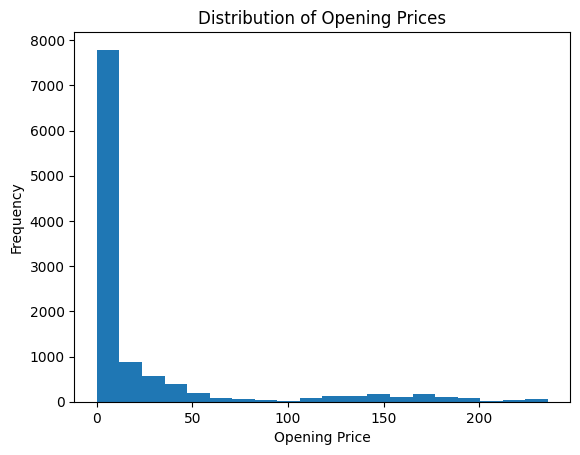

In [115]:
data['Open'].plot(kind='hist',
                  bins=20,
                  title="Distribution of Opening Prices")

plt.xlabel("Opening Price")

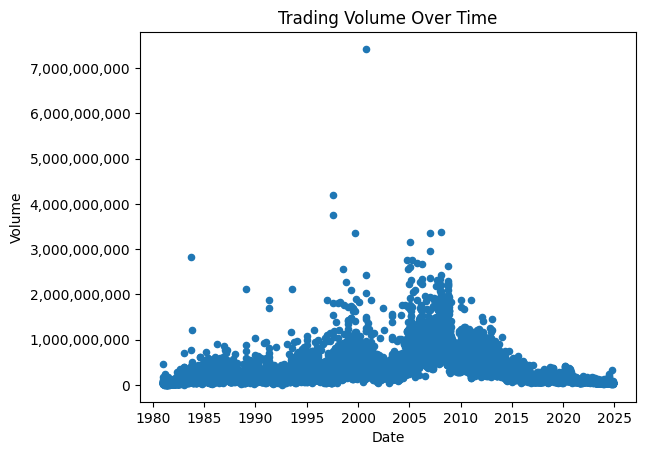

In [116]:
data.plot(kind='scatter',
          x='Date',
          y='Volume')

# Format the y-axis to avoid scientific notation
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

plt.title("Trading Volume Over Time")
plt.show()

<Axes: >

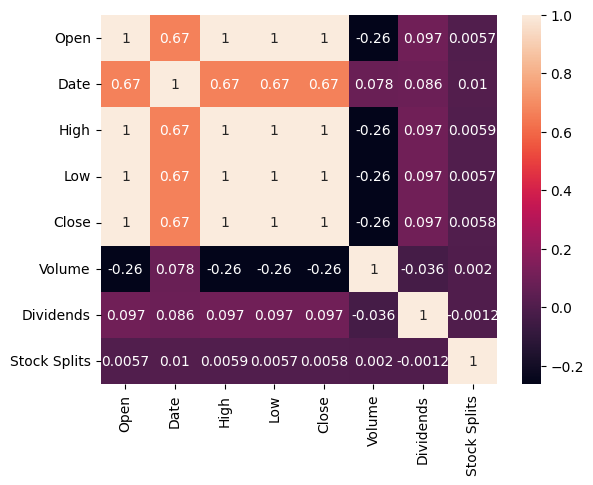

In [117]:
data_corr = data[['Open', 'Date', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']].corr()

sns.heatmap(data_corr, annot=True)

Calculating Features about data

In [118]:
# Assigning a quarter based on the month in the 'Date' column
data['Quarter'] = data['Date'].dt.quarter

data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Quarter
0,1980-12-12 05:00:00+00:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0,4
1,1980-12-15 05:00:00+00:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0,4
2,1980-12-16 05:00:00+00:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0,4
3,1980-12-17 05:00:00+00:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0,4
4,1980-12-18 05:00:00+00:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0,4


In [119]:
data['Week_number'] = data['Date'].dt.isocalendar().week
data['Week_day'] = data['Date'].dt.weekday
data['Month']  = data['Date'].dt.month

data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Quarter,Week_number,Week_day,Month
0,1980-12-12 05:00:00+00:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0,4,50,4,12
1,1980-12-15 05:00:00+00:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0,4,51,0,12
2,1980-12-16 05:00:00+00:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0,4,51,1,12
3,1980-12-17 05:00:00+00:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0,4,51,2,12
4,1980-12-18 05:00:00+00:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0,4,51,3,12


Calculating Features on price

In [120]:
#### Price Based Features #####

# Daily Range
data["Daily Range"] = data["High"] - data["Low"]

# Candle Size
data["Candle Size"] = (data["Close"] - data["Open"]).abs()

# 3. Direction
data["Direction"] = (data["Close"] > data["Open"]).astype(int)

# 4. Percentage Change
data["Percentage Change"] = ((data["Close"] - data["Open"]) / data["Open"]) * 100

# 5. Log Returns
data["Log Return"] = np.log(data["Close"] / data["Close"].shift(1))

# 6. Momentum (10-day)
data["Momentum_10"] = data["Close"] - data["Close"].shift(10)


# ===================== TREND AND MOVING AVERAGES =====================

# Simple Moving Average (SMA)
data["SMA_5"] = data["Close"].rolling(window=5).mean()
data["SMA_20"] = data["Close"].rolling(window=20).mean()

# Exponential Moving Average (EMA)
data["EMA_5"] = data["Close"].ewm(span=5, adjust=False).mean()
data["EMA_20"] = data["Close"].ewm(span=20, adjust=False).mean()


# ===================== VOLATILITY FEATURES =====================

# Rolling Standard Deviation (Volatility)
data["5-Day Volatility"] = data["Close"].rolling(window=5).std()


# Average True Range (ATR)
#data['TR'] = data[['High', 'Low', 'Close']].apply(
#    lambda row: max(row['High'] - row['Low'],
#                    abs(row['High'] - row['Close'].shift(1)),
#                    abs(row['Low'] - row['Close'].shift(1))) if not pd.isnull(row['Close'].shift(1)) else row['High'] - row['Low'], axis=1)
#data["ATR"] = data["TR"].rolling(window=14).mean()


# Bollinger Bands
data['Bollinger_SMA_20'] = data['Close'].rolling(window=20).mean()
data['Bollinger_Upper Band'] = data['Bollinger_SMA_20'] + (2 * data['Close'].rolling(window=20).std())
data['Bollinger_Lower Band'] = data['Bollinger_SMA_20'] - (2 * data['Close'].rolling(window=20).std())



# ===================== MOMENTUM AND OSCILLATORS =====================

# Relative Strength Index (RSI)
data['Change'] = data['Close'] - data['Close'].shift(1)
data['Gain'] = data['Change'].where(data['Change'] > 0, 0)
data['Loss'] = -data['Change'].where(data['Change'] < 0, 0)
data['Avg_Gain'] = data['Gain'].rolling(window=14).mean()
data['Avg_Loss'] = data['Loss'].rolling(window=14).mean()
data['RS'] = data['Avg_Gain'] / data['Avg_Loss']
data['RSI'] = 100 - (100 / (1 + data['RS']))



# Rate of Change (ROC)
data['ROC_10'] = ((data['Close'] - data['Close'].shift(10)) / data['Close'].shift(10)) * 100

# ===================== VOLUME-BASED FEATURES =====================

# Volume Moving Average
data['Volume_SMA_10'] = data['Volume'].rolling(window=10).mean()

# Volume Change (Percentage)
data['Volume Change'] = data['Volume'].pct_change() * 100

# On-Balance Volume (OBV)
data['OBV'] = (data['Volume'] * ((data['Close'] > data['Close'].shift(1)).astype(int) - (data['Close'] < data['Close'].shift(1)).astype(int))).cumsum()

# ===================== RETURN-BASED FEATURES =====================

# Daily Return
data['Daily Return'] = data['Close'].pct_change()

# Cumulative Return
data['Cumulative Return'] = (1 + data['Daily Return']).cumprod() - 1

# ===================== STATISTICAL FEATURES =====================

# Z-Score Normalization
data['Z-Score'] = (data['Close'] - data['Close'].rolling(window=20).mean()) / data['Close'].rolling(window=20).std()

# Skewness
data['Rolling Skewness'] = data['Close'].rolling(window=20).skew()

# Kurtosis
data['Rolling Kurtosis'] = data['Close'].rolling(window=20).kurt()

In [121]:
# ===================== RETURN-BASED FEATURES =====================

# Daily Return
#data['Daily Return'] = data['Close'].pct_change()
#data['Next Day Return'] = data['Daily Return'].shift(-1) * 100
#data['Next Week Return'] = data['Daily Return'].shift(-7)
#data['Next Month Return'] = data['Daily Return'].shift(-30)
#data['Next Year Return'] = data['Daily Return'].shift(-365)

# 2. Calculate returns over different periods
#data['7-Day Return'] = (data['Close'] / data['Close'].shift(7) - 1) * 100  # 7 days
#data['1-Month Return'] = (data['Close'] / data['Close'].shift(30) - 1) * 100  # 30 days
#data['6-Month Return'] = (data['Close'] / data['Close'].shift(182) - 1) * 100  # ~6 months
#data['1-Year Return'] = (data['Close'] / data['Close'].shift(365) - 1) * 100  # 1 year

#data.info()

In [122]:
#row_1000 = data.iloc[1000]

#print(row_1000)

#### Future Return

In [123]:
data = data.sort_values('Date')  # Making sure date is ordered

In [124]:
data['Daily Return'] = data['Close'].pct_change()
data['Next Day Return'] = data['Daily Return'].shift(-1) * 100
data['Next Week Return'] = data['Daily Return'].shift(-7) # 7 days
data['Next Month Return'] = data['Daily Return'].shift(-30) # 30 days
data['Next Year Return'] = data['Daily Return'].shift(-365) # 1 year

#### 3.1.7 Past Return

In [125]:
data['7-Day Return'] = (data['Close'] / data['Close'].shift(7) - 1) * 100  # 7 days
data['1-Month Return'] = (data['Close'] / data['Close'].shift(30) - 1) * 100  # 30 days
data['1-Year Return'] = (data['Close'] / data['Close'].shift(365) - 1) * 100  # 1 year

In [126]:
data.head(5)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Quarter,Week_number,...,Z-Score,Rolling Skewness,Rolling Kurtosis,Next Day Return,Next Week Return,Next Month Return,Next Year Return,7-Day Return,1-Month Return,1-Year Return
0,1980-12-12 05:00:00+00:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0,4,50,...,NaN,NaN,NaN,-5.217062,0.042199,-0.007751,0.000000,NaN,NaN,NaN
1,1980-12-15 05:00:00+00:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0,4,51,...,NaN,NaN,NaN,-7.339780,0.052628,-0.031248,-0.008695,NaN,NaN,NaN
2,1980-12-16 05:00:00+00:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0,4,51,...,NaN,NaN,NaN,2.475068,0.092309,-0.036288,-0.017543,NaN,NaN,NaN
3,1980-12-17 05:00:00+00:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0,4,51,...,NaN,NaN,NaN,2.899240,0.014084,-0.054397,0.000000,NaN,NaN,NaN
4,1980-12-18 05:00:00+00:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0,4,51,...,NaN,NaN,NaN,6.102898,-0.024304,-0.057519,-0.017856,NaN,NaN,NaN


In [127]:
nan_counts = data[['Daily Return', 'Next Day Return', 'Next Week Return',
                   'Next Month Return', 'Next Year Return', '7-Day Return',
                   '1-Month Return', '1-Year Return']].isna().sum()

nan_counts

Daily Return           1
Next Day Return        1
Next Week Return       7
Next Month Return     30
Next Year Return     365
7-Day Return           7
1-Month Return        30
1-Year Return        365
dtype: int64

In [128]:
data.head(10)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Quarter,Week_number,...,Z-Score,Rolling Skewness,Rolling Kurtosis,Next Day Return,Next Week Return,Next Month Return,Next Year Return,7-Day Return,1-Month Return,1-Year Return
0,1980-12-12 05:00:00+00:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0,4,50,...,NaN,NaN,NaN,-5.217062,0.042199,-0.007751,0.000000,NaN,NaN,NaN
1,1980-12-15 05:00:00+00:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0,4,51,...,NaN,NaN,NaN,-7.339780,0.052628,-0.031248,-0.008695,NaN,NaN,NaN
2,1980-12-16 05:00:00+00:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0,4,51,...,NaN,NaN,NaN,2.475068,0.092309,-0.036288,-0.017543,NaN,NaN,NaN
3,1980-12-17 05:00:00+00:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0,4,51,...,NaN,NaN,NaN,2.899240,0.014084,-0.054397,0.000000,NaN,NaN,NaN
4,1980-12-18 05:00:00+00:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0,4,51,...,NaN,NaN,NaN,6.102898,-0.024304,-0.057519,-0.017856,NaN,NaN,NaN
5,1980-12-19 05:00:00+00:00,0.097116,0.097545,0.097116,0.097116,48630400,0.0,0.0,4,51,...,NaN,NaN,NaN,4.866934,-0.028469,0.037557,0.018181,NaN,NaN,NaN
6,1980-12-22 05:00:00+00:00,0.101842,0.102273,0.101842,0.101842,37363200,0.0,0.0,4,52,...,NaN,NaN,NaN,4.219908,0.010989,0.036197,-0.035712,NaN,NaN,NaN
7,1980-12-23 05:00:00+00:00,0.106140,0.106570,0.106140,0.106140,46950400,0.0,0.0,4,52,...,NaN,NaN,NaN,5.262798,-0.021737,0.000000,-0.027776,7.391617,NaN,NaN
8,1980-12-24 05:00:00+00:00,0.111726,0.112156,0.111726,0.111726,48003200,0.0,0.0,4,52,...,NaN,NaN,NaN,9.230945,-0.044448,0.004366,0.000000,19.265581,NaN,NaN
9,1980-12-26 05:00:00+00:00,0.122039,0.122469,0.122039,0.122039,55574400,0.0,0.0,4,52,...,NaN,NaN,NaN,1.408379,-0.042633,-0.052171,-0.009524,40.594229,NaN,NaN


Correlation Matrix

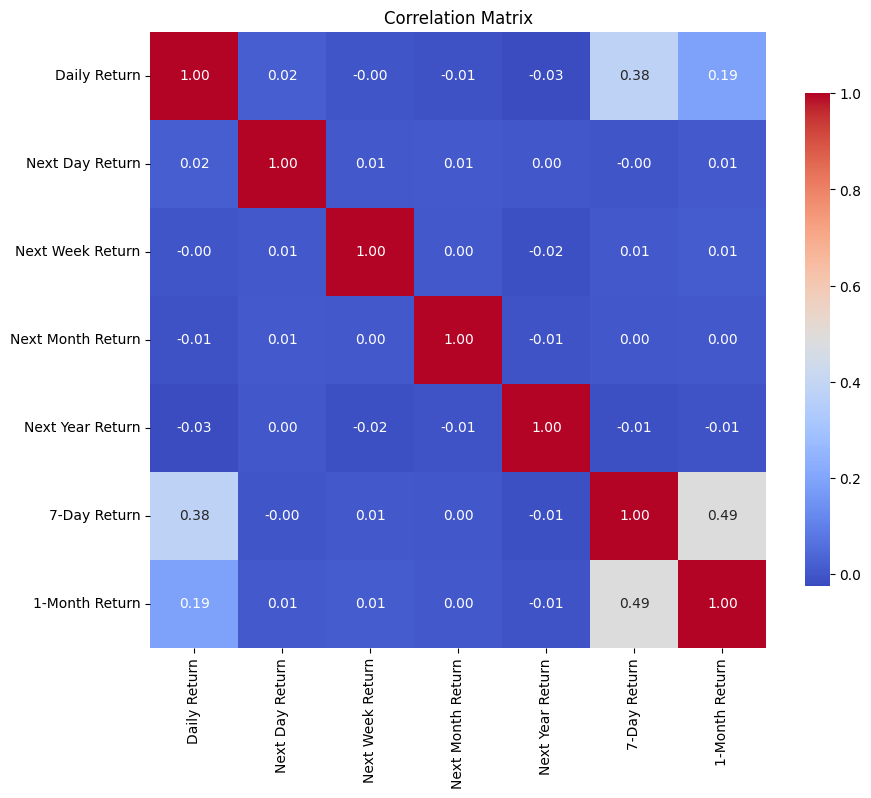

In [129]:
columns_to_corr = ['Daily Return', 'Next Day Return', 'Next Week Return',
                   'Next Month Return', 'Next Year Return', '7-Day Return',
                   '1-Month Return']

correlation_matrix = data[columns_to_corr].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title('Correlation Matrix')
plt.show()


### Model Training and Prediction

Mean Squared Error: 7.7435
R-Squared: -0.0481


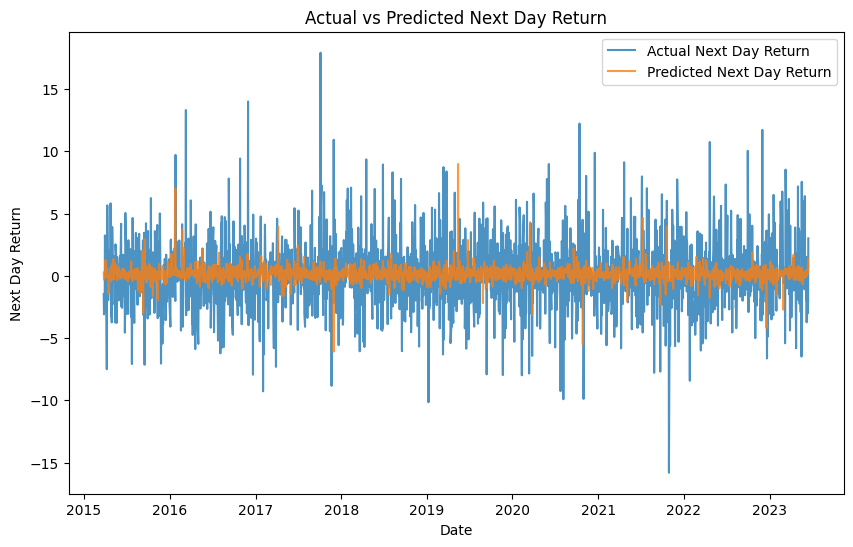

In [130]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Assuming 'data' is your DataFrame and 'target' is your target variable
data = data.dropna()  # Ensure there are no missing values
target = 'Next Day Return'  # Example target variable
features = [
    'Quarter', 'Week_number', 'Week_day',
    'Daily Range', 'Volume', 'Momentum_10', 'Volume Change',
    'Percentage Change', '7-Day Return', '1-Month Return',
    '1-Year Return', 'Daily Return', 'Next Week Return', 'Next Month Return', 'Next Year Return'
]

# Prepare the input data
inputData = data[features]
targetVariable = data[target]

# Split the data into training and testing sets
input_train, input_test, target_train, target_test = train_test_split(inputData, targetVariable, test_size=0.2, random_state=42, shuffle=True)

# Define the Random Forest model
model = RandomForestRegressor(
    n_estimators=500,  # Number of trees in the forest
    random_state=42,
    max_depth=None,  # You can set a maximum depth if needed
    min_samples_split=2,  # Minimum number of samples required to split an internal node
    min_samples_leaf=1,  # Minimum number of samples required to be at a leaf node
)

# Train the model
model.fit(input_train, target_train)

# Predict on the test set
target_pred = model.predict(input_test)

# Calculate Mean Squared Error and R-Squared
mse = mean_squared_error(target_test, target_pred)
r2 = r2_score(target_test, target_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R-Squared: {r2:.4f}")

# Plot predictions vs actuals
plt.figure(figsize=(10, 6))
plt.plot(data['Date'][-len(target_test):], target_test, label=f'Actual {target}', alpha=0.8)
plt.plot(data['Date'][-len(target_test):], target_pred, label=f'Predicted {target}', alpha=0.8)
plt.legend()
plt.title('Actual vs Predicted Next Day Return')
plt.xlabel('Date')
plt.ylabel('Next Day Return')
plt.show()

Mean Squared Error: 4.0001
R-Squared: -0.1492


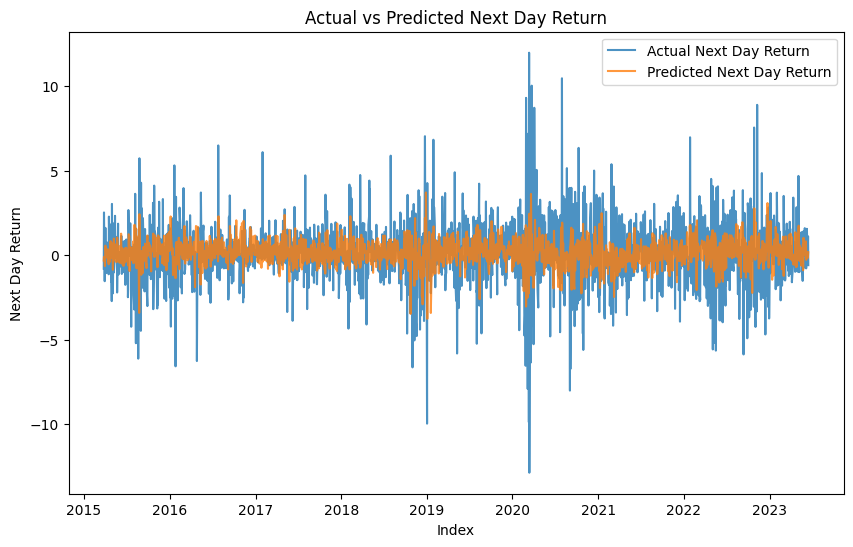

In [131]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
import matplotlib.pyplot as plt

# Assuming 'data' is your DataFrame and 'target' is your target variable
data = data.dropna()  # Ensure there are no missing values
target = 'Next Day Return'  # Example target variable
features = [
    'Quarter', 'Week_number', 'Week_day',
    'Daily Range', 'Volume', 'Momentum_10', 'Volume Change',
    'Percentage Change', '7-Day Return', '1-Month Return',
    '1-Year Return', 'Daily Return', 'Next Week Return', 'Next Month Return', 'Next Year Return'
]

# Prepare the input data
inputData = data[features]
targetVariable = data[target]

# Split the data into training and testing sets
input_train, input_test, target_train, target_test = train_test_split(inputData, targetVariable, test_size=0.2, random_state=42, shuffle=False)

# Create LightGBM dataset
train_data = lgb.Dataset(input_train, label=target_train)
test_data = lgb.Dataset(input_test, label=target_test, reference=train_data)

# Set parameters for LightGBM
params = {
    'objective': 'regression',
    'metric': 'mse',
    'boosting_type': 'gbdt',  # Gradient Boosting Decision Tree
    'num_leaves': 31,          # Number of leaves in one tree
    'learning_rate': 0.05,
    'feature_fraction': 0.9,   # Fraction of features to use
    'bagging_fraction': 0.8,    # Fraction of data to use for bagging
    'bagging_freq': 5,          # Frequency of bagging
    'verbose': -1               # Verbosity of the output
}

# Train the model
model = lgb.train(params, train_data, valid_sets=[test_data], num_boost_round=1000)

# Predict on the test set
target_pred = model.predict(input_test, num_iteration=model.best_iteration)

# Calculate Mean Squared Error and R-Squared
mse = mean_squared_error(target_test, target_pred)
r2 = r2_score(target_test, target_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R-Squared: {r2:.4f}")

# Plot predictions vs actuals
plt.figure(figsize=(10, 6))
plt.plot(data['Date'][-len(target_test):], target_test, label=f'Actual {target}', alpha=0.8)
plt.plot(data['Date'][-len(target_test):], target_pred, label=f'Predicted {target}', alpha=0.8)
plt.legend()
plt.title('Actual vs Predicted Next Day Return')
plt.xlabel('Index')
plt.ylabel('Next Day Return')
plt.show()